# Evaluating Classifiers
This exercise is about evaluation metrics for binary classification. 
The main focus is to evaluate a classification model, irrespective of which model (linear or non-linear) is being used.

**Info**
Recall that the confusion matrix for binary classification problems has the following structure:

$$
\begin{array}{cc|c|c|}
  & & \text{Predicted Negative} & \text{Predicted Positive} \\
\hline
\text{Actual Negative} & & TN & FP \\
\hline
\text{Actual Positive} & & FN & TP \\
\end{array}
$$
- **TN** - True Negative
- **FN** - False Negative 
- **FP** - False positive
- **TP** - True Positive



<article class="message">
    <div class="message-body">
        <strong>List of individual tasks</strong>
        <ul style="list-style: none;">
            <li>
            <a href="#import">Task 1: Generating Data</a>
            </li>
            <li>
            <a href="#First">Task 2: Training Support Vector Classifier</a>
            </li>
            <li>
            <a href="#accuracy">Task 3: Model accuracy</a>
            </li>
            <li>
            <a href="#classif_report">Task 4: Performance metrics</a>
            </li>
            <li>
            <a href="#svc_model">Task 5: Class Imbalance</a>
            </li>
            <li>
            <a href="#metrics">Task 6: ROC and Precision-Recall curves</a>
            </li>
        </ul>
    </div>
</article>

## Generating Data

---
**Task 1 (easy): Generating Data👩‍💻**
1. Run the cell below to generate a dataset comprising of 500 samples, 20 features, and 2 classes. This dataset is partitioned using an 80-20 train-test split.


---

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import confusion_matrix, accuracy_score, precision_recall_curve, auc, average_precision_score, roc_curve
from sklearn.svm import SVC, LinearSVC
from sklearn.dummy import DummyClassifier

import warnings
warnings.filterwarnings("ignore")


X,Y  = datasets.make_classification(n_samples=500, n_features=20, n_classes=2, random_state=1)
print('Dataset Size : ',X.shape,Y.shape)

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, train_size=0.80, test_size=0.20, stratify=Y, random_state=1)
print('Train/Test Size : ', X_train.shape, X_test.shape, Y_train.shape, Y_test.shape)

Dataset Size :  (500, 20) (500,)
Train/Test Size :  (400, 20) (100, 20) (400,) (100,)


In [ ]:
"""
Dataset Size: (500, 20) (500,)

(500, 20): This represents the feature matrix with 500 samples and 20 features.
(500,): This represents the target array (class labels) with 500 samples, one label per sample.


Train/Test Size: (400, 20) (100, 20) (400,) (100,)

(400, 20): The feature matrix for the training set with 400 samples and 20 features.
(100, 20): The feature matrix for the test set with 100 samples and 20 features.
(400,): The target array for the training set with 400 labels.
(100,): The target array for the test set with 100 labels.
"""

## Performance Metrics
In the following task you will evaluate the model's performance on the test data using different metrics. 

---
**Task 2 (easy): Training Support Vector Classifier👩‍💻**
1. Run the cell below to train a Linear Support Vector Classifier ([`LinearSVC`
](https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html)
).


---

In [11]:
classifier1 = LinearSVC(random_state=1, C=0.1)
classifier1.fit(X_train, Y_train)

LinearSVC(C=0.1, random_state=1)


---
**Task 3 (easy): Model accuracy👩‍💻**
Classification accuracy is given by 
$$ \text{accuracy} = \frac{\text{Number of correct predictions}}{\text{Total number of predictions}}$$
 
Run the following cell to make predictions using the `LinearSVC`
 on the test and training sets. Calculate accuracy by comparing predictions to actual labels: 
1. Calculate model accuracy on the training set.
2. Calculate model accuracy on the test set.
3. Run the cell below to construct and plot the confusion matrix of the model predictions on the training set. 
4. Construct and plot the confusion matrix of the model predictions on the test set. 


---

Train Accuracy :  0.9525
Test Accuracy :  0.93


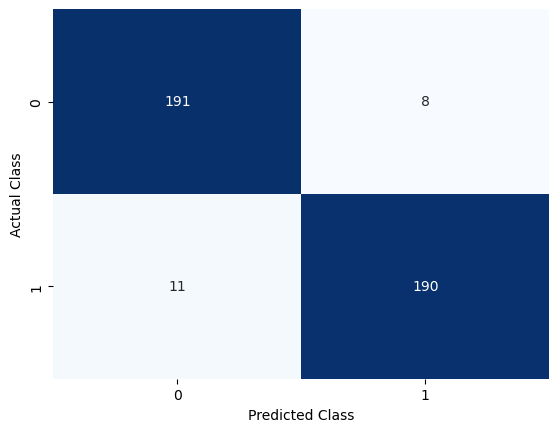

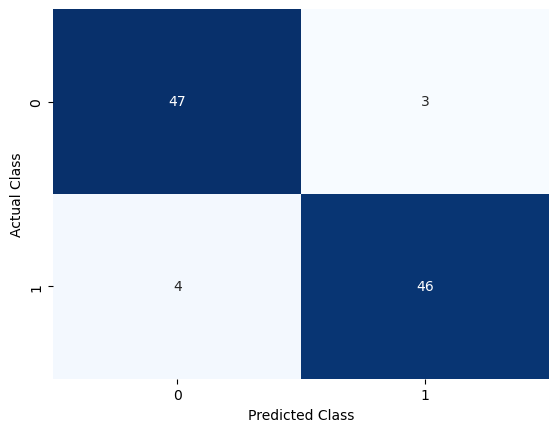

In [12]:
# Accuracy = Number of correct predictions / Total number of predictions
def accuracy(predictions,targets):
    """
    :param predictions: 1D-array of predicted classes for the data.
    :param targets: 1D-array of actual classes for the data.
     
    :return: fraction of correctly predicted points (num_correct/num_points).
    """

    acc = np.sum(predictions == targets)/len(predictions)
    return acc

Y_preds = classifier1.predict(X_test)
Y_preds2 = classifier1.predict(X_train)

# Accuracy of training set
train_acc = accuracy(Y_preds2, Y_train)
print('Train Accuracy : ', train_acc)

# Accuracy of test set
test_acc = accuracy(Y_preds, Y_test)
print('Test Accuracy : ', test_acc)

# Confusion Matrix - Training Set
conf_mat = confusion_matrix(Y_train, Y_preds2)
sns.heatmap(conf_mat, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.show()

# Confusion Matrix - Test Set
conf_mat_test = confusion_matrix(Y_test, Y_preds)
sns.heatmap(conf_mat_test, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.show()

**Performance metrics**

**Recall from the lecture**
Performance metrics such as **precision**, **recall**, **F$_1$-score**, and **specificity**  provide different views of the performance of the classifier.
- **Precision** - or positive predictive value, represents how many predictions of the positive class actually belong to that class. 

$$
\frac{𝑇𝑃}{𝑇𝑃+𝐹𝑃}
$$


- **Recall** -  also known as sensitivity, true positive rate, or hit rate assesses whether the classifier correctly identifies positive instances out of the total actual postive instances. 

$$
\frac{𝑇𝑃}{𝑇𝑃+𝐹𝑁} 
$$


- **F$_1$-score** - harmonic mean of precision & recall. 

$$
2∗\frac{\text{Precision}∗\text{Recall}}{\text{Precision}+\text{Recall}} 
$$


- **Specificity** - also known as the true negative rate, is the percentage of correctly predicted instances of the negative class. 

$$
\frac{TN}{TN+FP} 
$$





---
**Task 4 (easy): Performance metrics👩‍💻💡**
1. Use the confusion matrix from [Task 3](#accuracy) to find and store the true positive, false positive, true negative and false negative values. 

2. In the cell below calculate calculate the following evaluation metrics for the classification model:
    - Precision
    - Recall
    - F1-score
    - Specificity


3. Inspect the metrics and reflect on how they individually help in understanding and evaluating the performance of a classification model?



---

In [ ]:
# Find true positive, false pistive, true negative, false negative from the confusion matrix
tn, fp, fn, tp = conf_mat.ravel()
print('True Negative : ', tn)
print('False Positive : ', fp)
print('False Negative : ', fn)
print('True Positive : ', tp)

# Calculate Precision, Recall, F1 Score and Specificity
precision = tp/(tp+fp)
print('Precision : ', precision)

recall = tp/(tp+fn)
print('Recall : ', recall)

f1_score = 2*(precision*recall)/(precision+recall)
print('F1 Score : ', f1_score)

specificity = tn/(tn+fp)
print('Specificity : ', specificity)


# What does the metric tell us?
# High Precision: Fewer false positives.
# High Recall: Fewer false negatives.
# High F1 Score: High precision and high recall, more robust against imbalanced datasets.
# High Specificity: Fewer false positives.

True Negative :  191
False Positive :  8
False Negative :  11
True Positive :  190
Precision :  0.9595959595959596
Recall :  0.945273631840796
F1 Score :  0.9523809523809523
Specificity :  0.9597989949748744


## Imbalanced Classes
The cell below generates a dataset with 1,000 samples across 10 classes. Then an imbalanced dataset is created by combining 9 classes such that all samples in class 0 are marked as positive, while samples in the remaining classes are marked as negative. This results in a 10% positive and 90% negative distribution.


In [15]:
X, Y = datasets.make_classification(n_samples=1000, n_classes=10, n_informative=10)

# Mark the minority class as True
Y = (Y == 0).astype(int)

print('Dataset Size:', X.shape, Y.shape)

# Check the imbalance ratio
imbalance_ratio_actual = np.mean(Y)
print(f'Imbalance Ratio (Positive/Minority Class): {imbalance_ratio_actual:.2f}')

Dataset Size: (1000, 20) (1000,)
Imbalance Ratio (Positive/Minority Class): 0.10



---
**Task 5 (hard): Class Imbalance👩‍💻💡**
The following task will evaluate `classifier2`
 on the imbalanced dataset.
1. The cell below includes the classifier, variables to store performance metrics, and an incomplete for-loop that performs data splitting for 5-fold cross-validation. Complete the loop to:
    - Train `classifier2`
 on the training folds. 
    - Predict labels on the validation folds.
    - Calculate accuracy on the validation folds and store the values.


2. Run the cell below to plot the accuracy of the model on each fold. What does the plot tell you about classification performance?

3. Extend the loop to calculate the confusion matrix and the performance metrics on the validation sets (precision, recall, F1-Score, specificity). Print the average of each metric (use `np.nanmean()`
 as some of these metrics might inlcude NaNs). 

4. Why do some of the metrics return NaNs?

5. Is the model able to reliably identify the minority class? What are the implications for the model's performance and its practical utility?

6. Run the cell below to plot all the metrics in the same plot. Are certain metrics consistently lower, especially for the minority class? What might this indicate about the model’s handling of the imbalanced data?



---

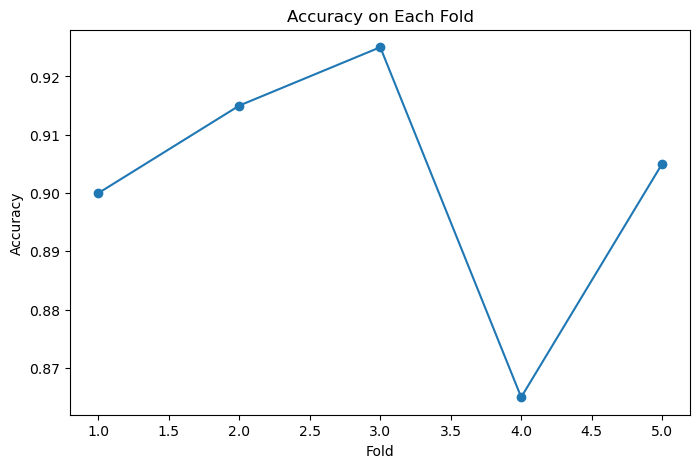

Average Metrics:
Accuracy: 0.902
Precision: 0.300
Recall: 0.034
F1-Score: 0.062
Specificity: 0.999


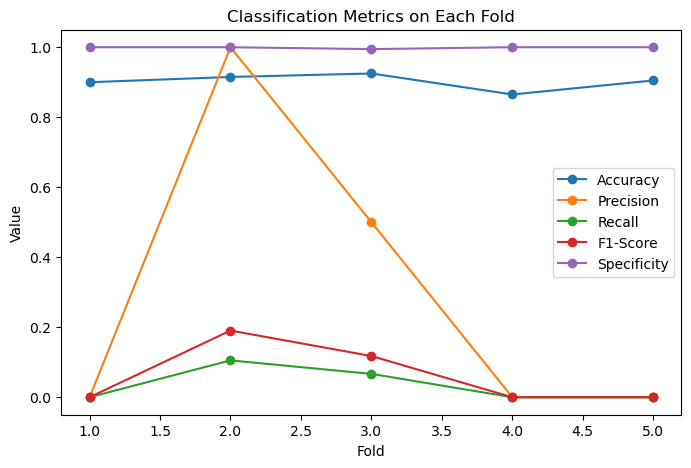

In [29]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import KFold
from sklearn.svm import SVC
import numpy as np
import matplotlib.pyplot as plt

# Initialize classifier and metric lists
classifier2 = SVC()
accuracies, precisions, recalls, f1_scores, specificities = [], [], [], [], []

# 5-Fold Cross-Validation
kf = KFold(n_splits=5, shuffle=True)
for train_idx_svc, test_idx_svc in kf.split(X):
    X_train, X_test = X[train_idx_svc], X[test_idx_svc]
    Y_train, Y_test = Y[train_idx_svc], Y[test_idx_svc]

    # Train the classifier on the training set
    classifier2.fit(X_train, Y_train)

    # Predict on the test set
    Y_preds = classifier2.predict(X_test)
    
    # Calculate accuracy
    acc = accuracy_score(Y_test, Y_preds)
    accuracies.append(acc)
    
    # Confusion matrix and metrics calculation
    tn, fp, fn, tp = confusion_matrix(Y_test, Y_preds).ravel()
    precision = precision_score(Y_test, Y_preds)
    recall = recall_score(Y_test, Y_preds)
    f1 = f1_score(Y_test, Y_preds)
    specificity = tn / (tn + fp)
    
    # Store metrics, handling NaN values
    precisions.append(precision)
    recalls.append(recall)
    f1_scores.append(f1)
    specificities.append(specificity)

# Step 2: Plot accuracy for each fold
plt.figure(figsize=(8, 5))
plt.plot(range(1, 6), accuracies, marker='o')
plt.title('Accuracy on Each Fold')
plt.xlabel('Fold')
plt.ylabel('Accuracy')
plt.show()

# Calculate and print average metrics using np.nanmean to ignore NaN values
print("Average Metrics:")
print(f"Accuracy: {np.mean(accuracies):.3f}")
print(f"Precision: {np.nanmean(precisions):.3f}")
print(f"Recall: {np.nanmean(recalls):.3f}")
print(f"F1-Score: {np.nanmean(f1_scores):.3f}")
print(f"Specificity: {np.nanmean(specificities):.3f}")

# Step 5: Plot all metrics on the same plot
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'Specificity']
metric_values = [accuracies, precisions, recalls, f1_scores, specificities]

plt.figure(figsize=(8, 5))
for i, metric_values_list in enumerate(metric_values):
    plt.plot(range(1, 6), metric_values_list, marker='o', label=metrics[i])

plt.title('Classification Metrics on Each Fold')
plt.xlabel('Fold')
plt.ylabel('Value')
plt.legend()
plt.show()


In [ ]:
"""
Metrics like precision and recall can be NaN when there are no positive predictions (or no true positives) in a fold. 
This can happen due to the class imbalance, where the model predicts only the majority class, leading to division by zero in metrics that involve positive samples.

Accuracy: 0.902 – High accuracy, but potentially misleading due to class imbalance (mostly correct on the majority class).
Precision: 0.300 – Low precision, indicating that many of the positive predictions are actually false positives.
Recall: 0.034 – Very low recall, showing the model struggles to identify the minority class (many false negatives).
F1Score: 0.062 – Low F1-score, confirming poor performance on the minority class (low balance of precision and recall).
Specificity: 0.999 – High specificity, meaning the model is very good at identifying the majority (negative) class correctly.

Conclusion: The model is biased towards the majority class, performing poorly on the minority class despite high accuracy.
"""

'\nMetrics like precision and recall can be NaN when there are no positive predictions (or no true positives) in a fold. \nThis can happen due to the class imbalance, where the model predicts only the majority class, leading to division by zero in metrics that involve positive samples.\n\nAccuracy: 0.902 – High accuracy, but potentially misleading due to class imbalance (mostly correct on the majority class).\nPrecision: 0.300 – Low precision, indicating that many of the positive predictions are actually false positives.\nRecall: 0.034 – Very low recall, showing the model struggles to identify the minority class (many false negatives).\nF1-Score: 0.062 – Low F1-score, confirming poor performance on the minority class (low balance of precision and recall).\nSpecificity: 0.999 – High specificity, meaning the model is very good at identifying the majority (negative) class correctly.\n'

## ROC Curves and Precision-Recall Curves
This task examines the ROC (Receiver Operating Characteristic) curve and the Precision-Recall curve for the classifier trained on the imbalanced dataset. The ROC curve illustrates the trade-off between true positive rate (sensitivity) and false positive rate, while the Precision-Recall curve shows the balance between precision and recall.

---
**Task 6 (medium): ROC and Precision-Recall curves👩‍💻💡**
The cell below divides the dataset (imbalanced) into a training and a test set. It also calculates both the ROC curve and the Precision-Recall curve and extracts relevant metrics such as: `fpr`
 (False Positive Rate), `tpr`
 (True Positive Rate or **recall**), and **precision**.
1. Run the cell below to plot the ROC curve and the Precision-Recall curve.
2. Use the confusion matrix metrics to argue how the plots provide different insights into the classification model's ability to handle class imbalance? 
3. Describe when and why you would prioritize one curve over the other when dealing with imbalanced data.


---

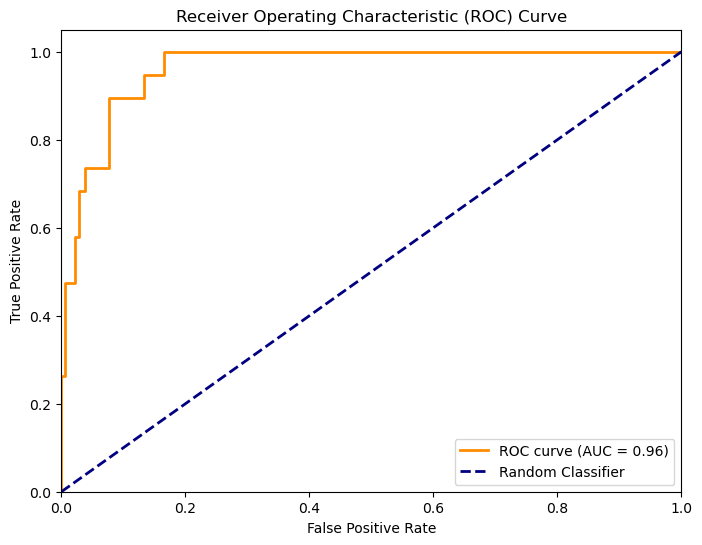

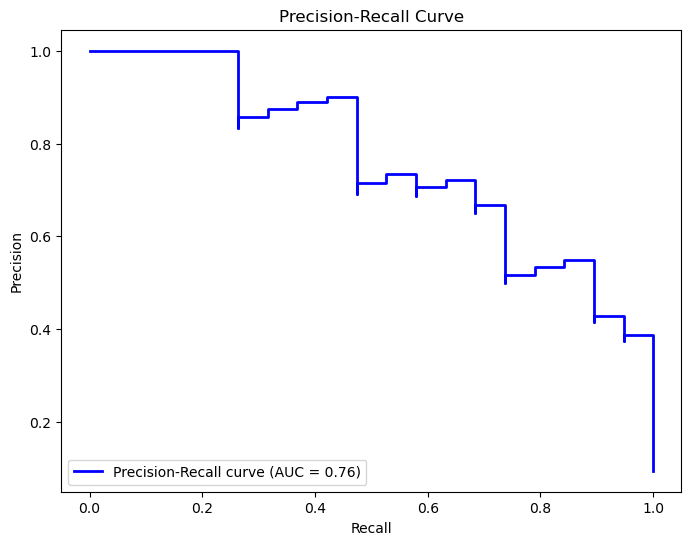

In [31]:
X_train, X_test = X[train_idx_svc], X[test_idx_svc]
Y_train, Y_test = Y[train_idx_svc], Y[test_idx_svc]

# ROC curve
decision_function = classifier2.decision_function(X_test)
fpr, tpr, _ = roc_curve(Y_test, decision_function)
roc_auc = auc(fpr, tpr)

# Calculate Precision-Recall curve
precision, recall, _ = precision_recall_curve(Y_test, decision_function)
pr_auc = average_precision_score(Y_test, decision_function)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (AUC = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')

# Plot Precision-Recall curve
plt.figure(figsize=(8, 6))
plt.step(recall, precision, color='b', where='post', lw=2, label='Precision-Recall curve (AUC = %0.2f)' % pr_auc)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc='lower left')
plt.show()

In [ ]:
"""
Explanation of Each Curve:

ROC Curve:
The ROC (Receiver Operating Characteristic) curve plots the True Positive Rate (TPR) (sensitivity or recall) against the False Positive Rate (FPR) at different thresholds.
True Positive Rate (TPR): The proportion of actual positives correctly identified (i.e., recall).
False Positive Rate (FPR): The proportion of actual negatives incorrectly identified as positive.
The Area Under the Curve (AUC) of the ROC curve represents the overall ability of the model to distinguish between classes. A higher AUC indicates better performance.

Precision-Recall Curve:
The Precision-Recall (PR) curve plots Precision against Recall at different thresholds
Precision: The proportion of positive predictions that are correct (True Positives / (True Positives + False Positives)).
Recall: The proportion of actual positives correctly identified (True Positives / (True Positives + False Negatives)).
The Average Precision (AP) score provides a summary of the precision-recall curve, giving insight into how well the model performs on the positive (minority) class.


Insights from Each Curve:

ROC Curve on Imbalanced Data:
The ROC curve can be misleading on imbalanced datasets because it considers both the positive and negative classes equally.
With imbalanced data, the False Positive Rate (x-axis of the ROC) may stay low simply because there are many more true negatives than false positives. This can result in a high AUC score even if the model fails to capture the minority class well.
In this scenario, the ROC curve may show an optimistic view of the classifier's performance, even if it performs poorly on the minority class.

Precision-Recall Curve on Imbalanced Data:
The Precision-Recall curve provides a more informative view for imbalanced datasets because it focuses on the positive (minority) class.
The PR curve highlights the trade-off between precision and recall for the minority class without being affected by the large number of true negatives.
A low precision-recall AUC indicates that the model struggles to detect the minority class, even if the overall accuracy or ROC AUC is high.


When to Prioritize Each Curve:

Prioritize the ROC Curve when:

The classes are relatively balanced.
The overall performance of the classifier on both classes is important.
You want to assess the model’s ability to distinguish between the two classes, taking both false positives and true positives into account.

Prioritize the Precision-Recall Curve when:

The data is highly imbalanced, with one class (often the positive or minority class) being much smaller.
The focus is on the classifier’s ability to identify the minority class (e.g., in cases of rare event detection, like fraud detection or medical diagnoses).
High precision or recall for the minority class is more valuable than overall accuracy or balanced class performance.


Summary
ROC Curve is generally more appropriate for balanced datasets and gives a global view of the model’s classification ability, considering both classes.
Precision-Recall Curve is more suitable for imbalanced datasets, as it directly measures the model’s effectiveness on the minority class, providing a realistic view of the classifier's performance where high precision or recall for the minority class is crucial.


"""